# A Transformer-Based Approach for Raw EEG Classification

### 1. Setup and Imports

Import necessary libraries and set up the environment.



In [1]:
%load_ext autoreload
%autoreload 2 
#%autoreload 2 fa in modo che, ogni volta che modifichi e salvi un file .py, Jupyter ricarichi automaticamente le modifiche nel notebook senza chiederti di riavviare il kernel!†

In [2]:
import numpy as np
from pathlib import Path
import re
import sys

src_path = Path('../src/eeg-bci-transformer-pipeline').resolve()
if str(src_path) not in sys.path:
    sys.path.append(str(src_path))
from datapreprocessing import EEGpreprocessing, EEGDataset
from train import EarlyStopper, EEGTrainer
from models import ScaledDotProductAttention, MultiHeadAttention, FeedForward, TransformerLayer, ConvolutionModule, EEGConformer, EEGTransformerConv1D

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import mne
import os
from sklearn.model_selection import KFold,GroupKFold
from sklearn.metrics import accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

### 2. Configuration and Hyperparameters

Define all model and training parameters

### 3. Data Loading and Preprocessing

Load the PhysioNet EEG Motor Movement/Imagery Dataset 

In [3]:
CURRENT_DIR = Path.cwd()

DATASET_PATH = (CURRENT_DIR.parent / "data" / "MotorMovement(03,07,011)") if CURRENT_DIR.name == "notebook" else (CURRENT_DIR / "data" / "MotorMovement(03,07,011)")

print(f"Percorso dataset utilizzato: {DATASET_PATH}")

edf_files = sorted(DATASET_PATH.glob("**/*.edf"))

file_records = []
for edf_path in edf_files:
    filename = edf_path.stem
    match = re.search(r'S(\d+)', filename, re.IGNORECASE)
    if match:
        subj_id = int(match.group(1))
        file_records.append({'path': edf_path, 'subject_id': subj_id})

file_subject_ids = np.array([r['subject_id'] for r in file_records])
unique_subjects = np.unique(file_subject_ids)

# Split riproducibile sui SOGGETTI (Test set isolato)
np.random.seed(42)
shuffled_subjects = unique_subjects.copy()
np.random.shuffle(shuffled_subjects)

test_subjects = set(shuffled_subjects[:11])
train_val_subjects = set(shuffled_subjects[11:])

train_val_records = [r for r in file_records if r['subject_id'] in train_val_subjects]
test_records = [r for r in file_records if r['subject_id'] in test_subjects]

print(f"File EDF for Train/Validation: {len(train_val_records)}")
print(f"File EDF for TEST: {len(test_records)}")

Percorso dataset utilizzato: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorMovement(03,07,011)
File EDF for Train/Validation: 294
File EDF for TEST: 33


Apply preprocessing  #momontaneamente lo faccio solo sul train/val perchè non sono sicura vada fatto sul test, riparlarne con luca

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import mne

X_raw_list = []
y_list = []
subject_ids_list = []
psd_records = []  # 📊 Lista per salvare i valori numerici della PSD

for i, rec in enumerate(train_val_records):
    file_path = rec['path']
    subj_id = rec['subject_id']

    raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False)

    pipeline = EEGpreprocessing(raw)
    pipeline.bandpassfilter(l_freq=8.0, h_freq=30.0, target_sfreq=160.0)
    epochs_mne = pipeline.epoching(tmin=0.0, tmax=4.0)

    # 1. CALCOLO CORRETTO DELLA PSD (Metodo moderno di MNE)
    psd_object = epochs_mne.compute_psd(fmin=1, fmax=40, method='welch')
    
    # 2. ESTRAZIONE DEI VALORI NUMERICI DELLA PSD
    psd_values, freqs = psd_object.get_data(return_freqs=True) 
    # Shape di psd_values: (n_epochs, n_channels, n_freqs)
    
    # Salviamo i valori numerici associati al soggetto
    psd_records.append({
        'subject_id': subj_id,
        'frequencies': freqs,                # Vettore delle frequenze (es. 1 Hz, 2 Hz, ...)
        'psd_data': psd_values,              # Valori di potenza spettrale
        'mean_power_per_channel': np.mean(psd_values, axis=(0, 2)) # Potenza media per canale
    })


    if len(epochs_mne) == 0:
        continue
    
    # Estraiamo i dati grezzi delle epoche
    X_raw = epochs_mne.get_data(copy=True) 

    y = epochs_mne.events[:, -1]
    event_id = epochs_mne.event_id
    labels = np.zeros(len(y), dtype=np.int64)
    labels[y == event_id['Left']] = 0
    labels[y == event_id['Right']] = 1

    X_raw_list.append(X_raw)
    y_list.append(labels)
    subject_ids_list.extend([subj_id] * len(X_raw))

Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Effective window size : 4.006 (s)
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Effective window size : 4.006 (s)
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Effective window size : 4.006 (s)
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 project

/tmp/ipykernel_227515/785558903.py:14: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False)
/tmp/ipykernel_227515/785558903.py:14: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False)


Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
12 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 12 events and 641 original time points ...
0 bad epochs dropped
Effective window size : 4.006 (s)
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
12 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 12 events and 641 original time points ...
0 bad epochs dropped
Effective window size : 4.006 (s)


/tmp/ipykernel_227515/785558903.py:14: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False)


Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Effective window size : 4.006 (s)
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Effective window size : 4.006 (s)
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Effective window size : 4.006 (s)
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 project

In [19]:
'''
for i, record in enumerate(psd_records[:4]):
    print(f"--- Paziente {i+1} ---")
    print(f"Subject ID: {record['subject_id']}")
    print(f"Shape della PSD (epoche, canali, frequenze): {record['psd_data'].shape}")
    print(f"Potenza media per canale (primi 5 canali): {record['mean_power_per_channel'][:63]}")
    print("-" * 30)
'''

'\nfor i, record in enumerate(psd_records[:4]):\n    print(f"--- Paziente {i+1} ---")\n    print(f"Subject ID: {record[\'subject_id\']}")\n    print(f"Shape della PSD (epoche, canali, frequenze): {record[\'psd_data\'].shape}")\n    print(f"Potenza media per canale (primi 5 canali): {record[\'mean_power_per_channel\'][:63]}")\n    print("-" * 30)\n'

Convert to PyTorch tensors

In [5]:
X_training_validation_raw = np.concatenate(X_raw_list, axis=0)
y_training_validation = np.concatenate(y_list, axis=0)
subjects_ids_training_validation = np.array(subject_ids_list)

print(f"Dimensioni X_train_val grezzo: {X_training_validation_raw.shape}")
print(f"Dimensioni y_train_val: {y_training_validation.shape}")
print("Distribuzione etichette:", np.unique(y_training_validation, return_counts=True))

Dimensioni X_train_val grezzo: (4402, 64, 641)
Dimensioni y_train_val: (4402,)
Distribuzione etichette: (array([0, 1]), array([2203, 2199]))


In [8]:
if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("🚀 Dispositivo rilevato: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print("🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("⚠️ Dispositivo rilevato: CPU")

🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)


### Cross-Individual 3-Fold Cross-Validation and Random grid search to tuning hyperparameters

# GroupKFold + ReduceLROnPlateau + gradient clipping

🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)

--- INIZIO TRAINING & VALIDAZIONE - FOLD 1/5 (Batch Size = 64) ---
Epoch 01/30: train_loss=0.69440, val_loss=0.69293, val_acc=53.54%
Epoch 02/30: train_loss=0.69245, val_loss=0.69277, val_acc=52.85%
Epoch 03/30: train_loss=0.69200, val_loss=0.69269, val_acc=52.73%
Epoch 04/30: train_loss=0.69119, val_loss=0.69174, val_acc=53.54%
Epoch 05/30: train_loss=0.68997, val_loss=0.69155, val_acc=53.31%
Epoch 06/30: train_loss=0.68958, val_loss=0.69047, val_acc=54.36%
Epoch 07/30: train_loss=0.68590, val_loss=0.68872, val_acc=55.05%
Epoch 08/30: train_loss=0.68382, val_loss=0.68719, val_acc=55.05%
Epoch 09/30: train_loss=0.68091, val_loss=0.68514, val_acc=55.87%
Epoch 10/30: train_loss=0.67879, val_loss=0.68398, val_acc=55.75%
Epoch 11/30: train_loss=0.67369, val_loss=0.67913, val_acc=59.70%
Epoch 12/30: train_loss=0.66810, val_loss=0.67550, val_acc=59.00%
Epoch 13/30: train_loss=0.65848, val_loss=0.67540, val_acc=58.65%
Epoch 14/30: train_loss=0.65148,

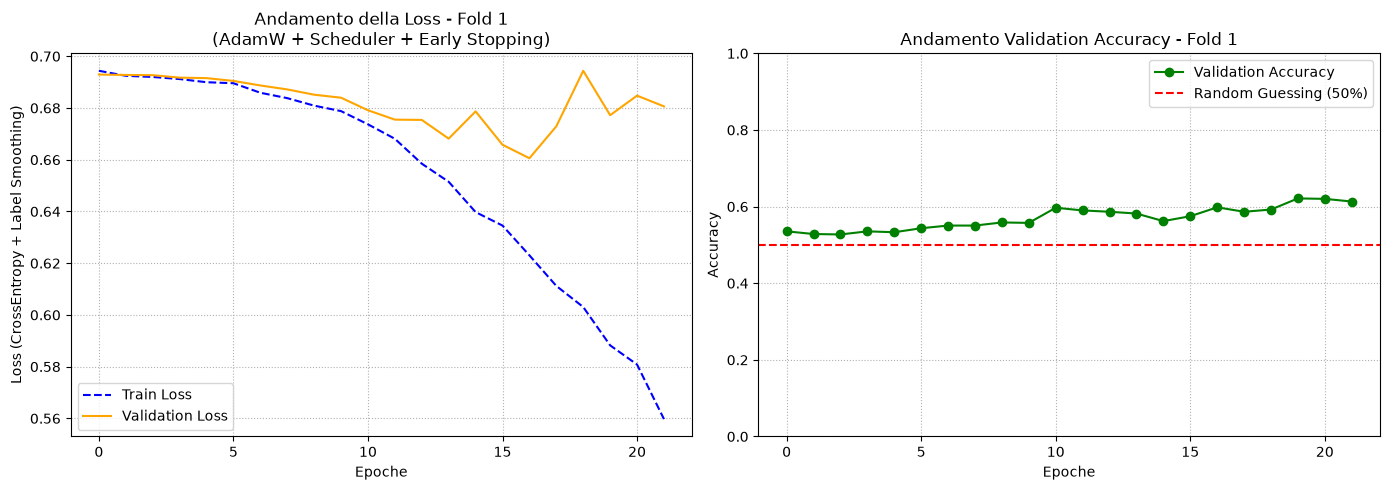


--- INIZIO TRAINING & VALIDAZIONE - FOLD 2/5 (Batch Size = 64) ---
Epoch 01/30: train_loss=0.69412, val_loss=0.69279, val_acc=50.41%
Epoch 02/30: train_loss=0.69297, val_loss=0.69241, val_acc=51.68%
Epoch 03/30: train_loss=0.69228, val_loss=0.69221, val_acc=53.08%
Epoch 04/30: train_loss=0.69093, val_loss=0.69192, val_acc=53.08%
Epoch 05/30: train_loss=0.69062, val_loss=0.69169, val_acc=52.73%
Epoch 06/30: train_loss=0.68939, val_loss=0.69112, val_acc=55.05%
Epoch 07/30: train_loss=0.68786, val_loss=0.69072, val_acc=53.19%
Epoch 08/30: train_loss=0.68690, val_loss=0.69010, val_acc=52.61%
Epoch 09/30: train_loss=0.68344, val_loss=0.68769, val_acc=54.94%
Epoch 10/30: train_loss=0.67888, val_loss=0.68581, val_acc=54.01%
Epoch 11/30: train_loss=0.67438, val_loss=0.68566, val_acc=54.47%
Epoch 12/30: train_loss=0.66617, val_loss=0.68121, val_acc=54.82%
Epoch 13/30: train_loss=0.65565, val_loss=0.68188, val_acc=57.49%
Epoch 14/30: train_loss=0.65164, val_loss=0.67729, val_acc=58.19%
Epoch 15

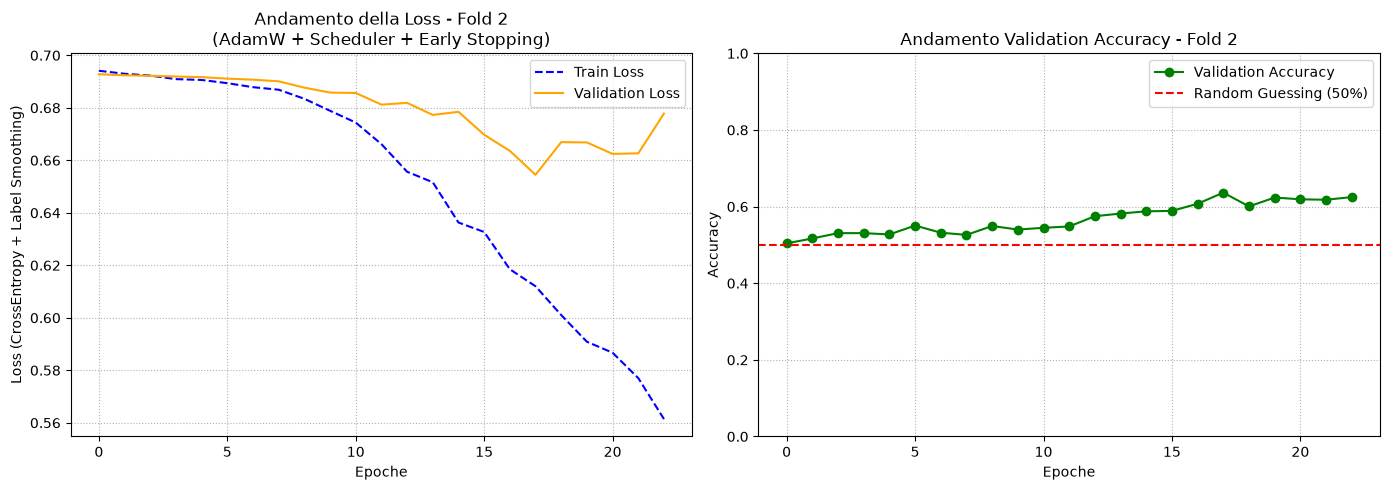


--- INIZIO TRAINING & VALIDAZIONE - FOLD 3/5 (Batch Size = 64) ---
Epoch 01/30: train_loss=0.69545, val_loss=0.69181, val_acc=50.56%
Epoch 02/30: train_loss=0.69334, val_loss=0.69091, val_acc=52.02%
Epoch 03/30: train_loss=0.69370, val_loss=0.68958, val_acc=52.13%
Epoch 04/30: train_loss=0.69249, val_loss=0.68820, val_acc=54.60%
Epoch 05/30: train_loss=0.69184, val_loss=0.68761, val_acc=59.08%
Epoch 06/30: train_loss=0.69082, val_loss=0.68609, val_acc=62.00%
Epoch 07/30: train_loss=0.69032, val_loss=0.68510, val_acc=60.20%
Epoch 08/30: train_loss=0.69001, val_loss=0.68315, val_acc=65.47%
Epoch 09/30: train_loss=0.68886, val_loss=0.68132, val_acc=64.01%
Epoch 10/30: train_loss=0.68628, val_loss=0.67956, val_acc=60.65%
Epoch 11/30: train_loss=0.68672, val_loss=0.67499, val_acc=64.01%
Epoch 12/30: train_loss=0.68222, val_loss=0.66957, val_acc=64.24%
Epoch 13/30: train_loss=0.68005, val_loss=0.66287, val_acc=69.06%
Epoch 14/30: train_loss=0.67361, val_loss=0.65676, val_acc=70.18%
Epoch 15

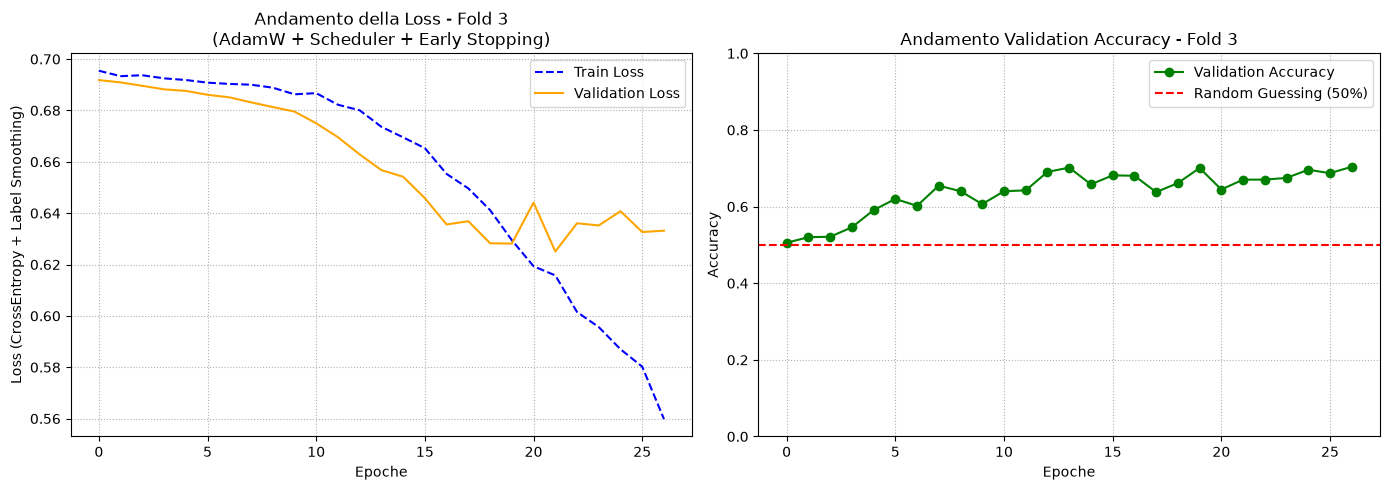


--- INIZIO TRAINING & VALIDAZIONE - FOLD 4/5 (Batch Size = 64) ---
Epoch 01/30: train_loss=0.69799, val_loss=0.69333, val_acc=49.55%
Epoch 02/30: train_loss=0.69398, val_loss=0.69215, val_acc=49.78%
Epoch 03/30: train_loss=0.69409, val_loss=0.69114, val_acc=50.45%
Epoch 04/30: train_loss=0.69266, val_loss=0.69025, val_acc=54.14%
Epoch 05/30: train_loss=0.69214, val_loss=0.68935, val_acc=54.36%
Epoch 06/30: train_loss=0.69073, val_loss=0.68874, val_acc=55.48%
Epoch 07/30: train_loss=0.68859, val_loss=0.68655, val_acc=57.16%
Epoch 08/30: train_loss=0.68813, val_loss=0.68439, val_acc=57.16%
Epoch 09/30: train_loss=0.68622, val_loss=0.68394, val_acc=59.51%
Epoch 10/30: train_loss=0.68337, val_loss=0.67957, val_acc=57.83%
Epoch 11/30: train_loss=0.67964, val_loss=0.67961, val_acc=56.60%
Epoch 12/30: train_loss=0.67601, val_loss=0.68041, val_acc=56.38%
Epoch 13/30: train_loss=0.67020, val_loss=0.68004, val_acc=57.16%
Epoch 14/30: train_loss=0.65737, val_loss=0.68607, val_acc=58.50%
Epoch 15

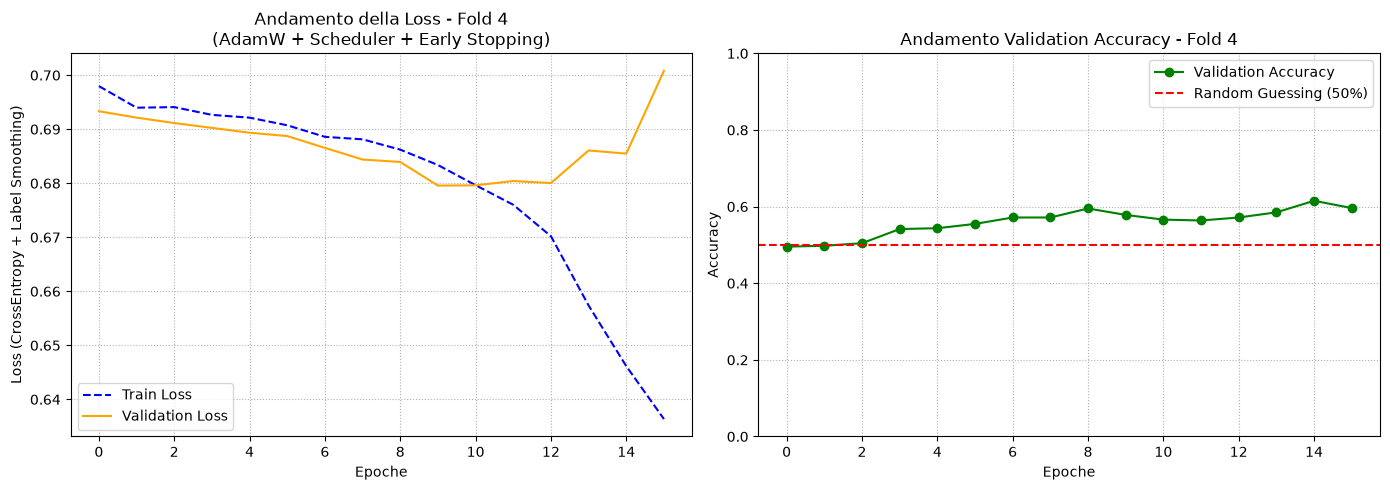


--- INIZIO TRAINING & VALIDAZIONE - FOLD 5/5 (Batch Size = 64) ---
Epoch 01/30: train_loss=0.69826, val_loss=0.69316, val_acc=50.22%
Epoch 02/30: train_loss=0.69672, val_loss=0.69274, val_acc=49.89%
Epoch 03/30: train_loss=0.69416, val_loss=0.69217, val_acc=51.12%
Epoch 04/30: train_loss=0.69165, val_loss=0.69157, val_acc=54.25%
Epoch 05/30: train_loss=0.69244, val_loss=0.69117, val_acc=52.13%
Epoch 06/30: train_loss=0.69083, val_loss=0.69012, val_acc=54.14%
Epoch 07/30: train_loss=0.68773, val_loss=0.68928, val_acc=59.06%
Epoch 08/30: train_loss=0.68757, val_loss=0.68789, val_acc=57.83%
Epoch 09/30: train_loss=0.68542, val_loss=0.68546, val_acc=58.50%
Epoch 10/30: train_loss=0.68298, val_loss=0.68540, val_acc=55.03%
Epoch 11/30: train_loss=0.68021, val_loss=0.68194, val_acc=59.40%
Epoch 12/30: train_loss=0.67279, val_loss=0.68168, val_acc=56.15%
Epoch 13/30: train_loss=0.66622, val_loss=0.67254, val_acc=62.75%
Epoch 14/30: train_loss=0.65691, val_loss=0.66992, val_acc=60.96%
Epoch 15

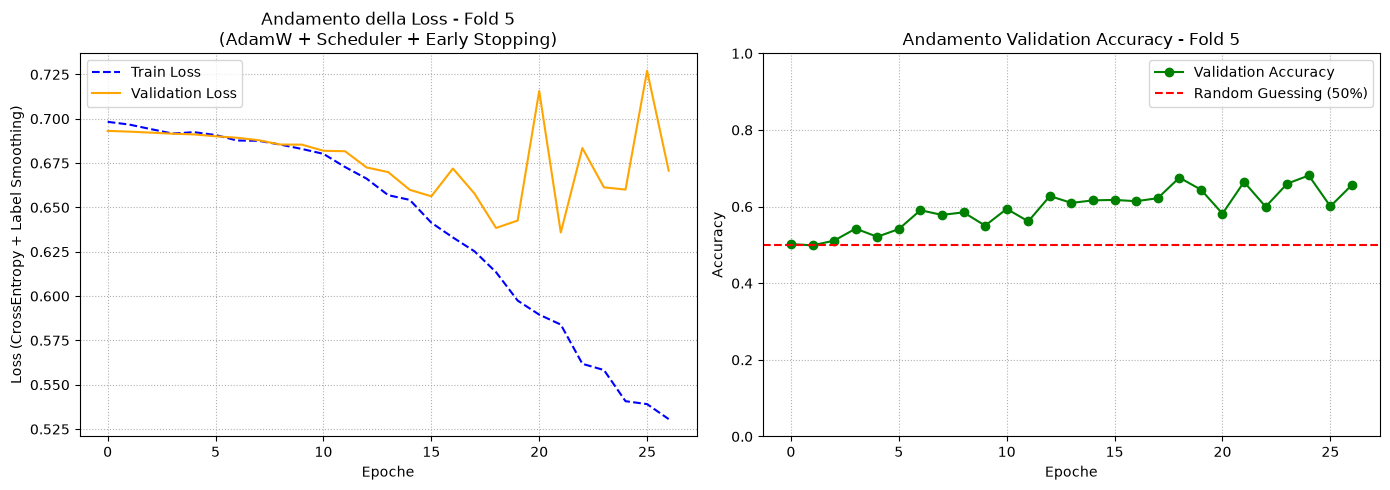

In [9]:
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt

# 1. Configurazione del Dispositivo (MPS / CUDA / CPU)
if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("🚀 Dispositivo rilevato: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print("🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("⚠️ Dispositivo rilevato: CPU")

# 2. Parametri di Configurazione
BATCH_SIZE = 64
EPOCHS = 30
LR = 1e-4
WEIGHT_DECAY = 1e-1
ALPHA_NOISE = 0.01

gkf = GroupKFold(n_splits=5)

# ==========================================
# 3. CICLO DI TRAINING CON FOLD E TRAINER PERSONALIZZATO
# ==========================================
for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- INIZIO TRAINING & VALIDAZIONE - FOLD {fold + 1}/5 (Batch Size = {BATCH_SIZE}) ---")

    # A. Divisione dei dati grezzi in base al fold del GroupKFold
    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]

    # B. Calcolo Media e Std per-canale ESCLUSIVAMENTE sul Training Set
    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    # C. Normalizzazione + Data Augmentation (Rumore Gaussiano) solo sul Train
    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    # D. Normalizzazione pura sul Validation Set (usando media e std del Train)
    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    # E. Creazione Dataset e DataLoader PyTorch
    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

    # F. Inizializzazione del Modello EEG Conformer
    model = EEGConformer(
        num_channels=64, time_steps=641, d_model=32, 
        nhead=4, num_layers=1, d_ff=128, dropout=0.4, num_classes=2
    ).to(device)
    
    # G. Ottimizzatore (AdamW), Loss (con Label Smoothing) e Scheduler (Cosine Annealing)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, 
        mode='min',       # Monitora la discesa della validation loss
        factor=0.5,       # Dimezza il learning rate quando si attiva (lr = lr * 0.5)
        patience=3,       # Se per 3 epoche la val loss non migliora, agisce
        )

    # H. Inizializzazione della tua classe EEGTrainer (che gestisce Early Stopper e Scheduler)
    trainer = EEGTrainer(
        model=model, 
        criterion=criterion, 
        optimizer=optimizer,  
        device=device
    )

    # I. Avvio dell'addestramento tramite il metodo della classe
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(
        train_loader=train_loader, 
        val_loader=val_loader, 
        epochs=EPOCHS,
        scheduler=scheduler
    )

    print(f"✅ Fold {fold + 1} completato | Miglior Val Acc: {best_val_acc:.4f} | Max Val Acc: {max(val_accuracies)*100:.2f}%")

    # ==========================================
    # L. PLOT DELLE CURVE DI LOSS E ACCURACY PER IL FOLD
    # ==========================================
    plt.figure(figsize=(14, 5))

    # Pannello 1: Loss
    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Andamento della Loss - Fold {fold + 1}\n(AdamW + Scheduler + Early Stopping)')
    plt.xlabel('Epoche')
    plt.ylabel('Loss (CrossEntropy + Label Smoothing)')
    plt.legend()
    plt.grid(True, linestyle=':')

    # Pannello 2: Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.axhline(y=0.5, color='red', linestyle='--', label='Random Guessing (50%)')
    plt.title(f'Andamento Validation Accuracy - Fold {fold + 1}')
    plt.xlabel('Epoche')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()

  

🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)

--- INIZIO TRAINING & VALIDAZIONE - FOLD 1/5 (Batch Size = 64) ---
Epoch 01/100: train_loss=0.69643, val_loss=0.69325, val_acc=49.83%
Epoch 02/100: train_loss=0.69421, val_loss=0.69299, val_acc=50.75%
Epoch 03/100: train_loss=0.69149, val_loss=0.69260, val_acc=52.61%
Epoch 04/100: train_loss=0.68971, val_loss=0.69231, val_acc=52.50%
Epoch 05/100: train_loss=0.68950, val_loss=0.69206, val_acc=52.96%
Epoch 06/100: train_loss=0.69013, val_loss=0.69176, val_acc=53.43%
Epoch 07/100: train_loss=0.68875, val_loss=0.69128, val_acc=54.59%
Epoch 08/100: train_loss=0.68864, val_loss=0.69103, val_acc=53.77%
Epoch 09/100: train_loss=0.68789, val_loss=0.69022, val_acc=53.77%
Epoch 10/100: train_loss=0.68489, val_loss=0.68947, val_acc=55.28%
Epoch 11/100: train_loss=0.68397, val_loss=0.68820, val_acc=54.94%
Epoch 12/100: train_loss=0.68213, val_loss=0.68741, val_acc=55.40%
Epoch 13/100: train_loss=0.67860, val_loss=0.68664, val_acc=55.63%
Epoch 14/100: train

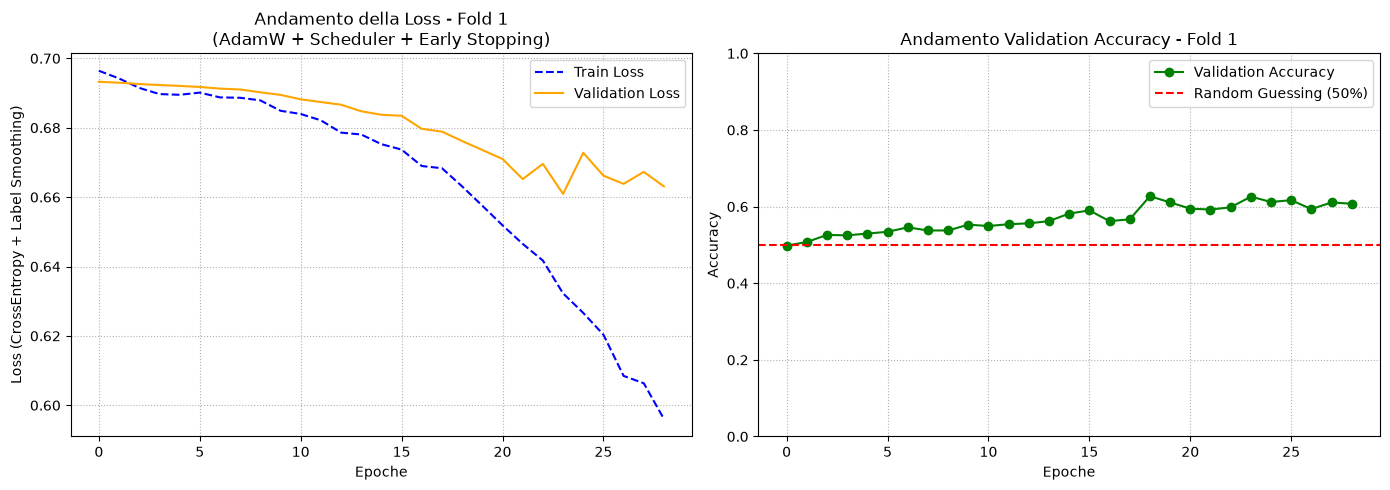

In [10]:
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt

# 1. Configurazione del Dispositivo (MPS / CUDA / CPU)
if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("🚀 Dispositivo rilevato: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print("🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("⚠️ Dispositivo rilevato: CPU")

# 2. Parametri di Configurazione
BATCH_SIZE = 64
EPOCHS = 100
LR = 5e-5
WEIGHT_DECAY = 1e-1
ALPHA_NOISE = 0.01

gkf = GroupKFold(n_splits=5)

# ==========================================
# 3. CICLO DI TRAINING CON FOLD E TRAINER PERSONALIZZATO
# ==========================================
for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- INIZIO TRAINING & VALIDAZIONE - FOLD {fold + 1}/5 (Batch Size = {BATCH_SIZE}) ---")

    # A. Divisione dei dati grezzi in base al fold del GroupKFold
    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]

    # B. Calcolo Media e Std per-canale ESCLUSIVAMENTE sul Training Set
    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    # C. Normalizzazione + Data Augmentation (Rumore Gaussiano) solo sul Train
    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    # D. Normalizzazione pura sul Validation Set (usando media e std del Train)
    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    # E. Creazione Dataset e DataLoader PyTorch
    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

    # F. Inizializzazione del Modello EEG Conformer
    model = EEGConformer(
        num_channels=64, time_steps=641, d_model=32, 
        nhead=4, num_layers=1, d_ff=128, dropout=0.4, num_classes=2
    ).to(device)
    
    # G. Ottimizzatore (AdamW), Loss (con Label Smoothing) e Scheduler (Cosine Annealing)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, 
        mode='min',       # Monitora la discesa della validation loss
        factor=0.5,       # Dimezza il learning rate quando si attiva (lr = lr * 0.5)
        patience=3,       # Se per 3 epoche la val loss non migliora, agisce
        )

    # H. Inizializzazione della tua classe EEGTrainer (che gestisce Early Stopper e Scheduler)
    trainer = EEGTrainer(
        model=model, 
        criterion=criterion, 
        optimizer=optimizer,  
        device=device
    )

    # I. Avvio dell'addestramento tramite il metodo della classe
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(
        train_loader=train_loader, 
        val_loader=val_loader, 
        epochs=EPOCHS,
        scheduler=scheduler
    )

    print(f"✅ Fold {fold + 1} completato | Miglior Val Acc: {best_val_acc:.4f} | Max Val Acc: {max(val_accuracies)*100:.2f}%")

    # ==========================================
    # L. PLOT DELLE CURVE DI LOSS E ACCURACY PER IL FOLD
    # ==========================================
    plt.figure(figsize=(14, 5))

    # Pannello 1: Loss
    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Andamento della Loss - Fold {fold + 1}\n(AdamW + Scheduler + Early Stopping)')
    plt.xlabel('Epoche')
    plt.ylabel('Loss (CrossEntropy + Label Smoothing)')
    plt.legend()
    plt.grid(True, linestyle=':')

    # Pannello 2: Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.axhline(y=0.5, color='red', linestyle='--', label='Random Guessing (50%)')
    plt.title(f'Andamento Validation Accuracy - Fold {fold + 1}')
    plt.xlabel('Epoche')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()

    break
  

🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)

--- INIZIO TRAINING & VALIDAZIONE - FOLD 1/5 (Batch Size = 32) ---
Epoch 01/100: train_loss=0.69289, val_loss=0.69324, val_acc=49.83%
Epoch 02/100: train_loss=0.69383, val_loss=0.69313, val_acc=49.83%
Epoch 03/100: train_loss=0.69362, val_loss=0.69306, val_acc=50.29%
Epoch 04/100: train_loss=0.69287, val_loss=0.69301, val_acc=51.68%
Epoch 05/100: train_loss=0.69294, val_loss=0.69298, val_acc=52.26%
Epoch 06/100: train_loss=0.69284, val_loss=0.69294, val_acc=52.61%
Epoch 07/100: train_loss=0.69347, val_loss=0.69288, val_acc=51.34%
Epoch 08/100: train_loss=0.69347, val_loss=0.69282, val_acc=50.64%
Epoch 09/100: train_loss=0.69253, val_loss=0.69276, val_acc=51.22%
Epoch 10/100: train_loss=0.69243, val_loss=0.69279, val_acc=50.99%
Epoch 11/100: train_loss=0.69215, val_loss=0.69278, val_acc=51.10%
Epoch 12/100: train_loss=0.69224, val_loss=0.69271, val_acc=51.45%
Epoch 13/100: train_loss=0.69191, val_loss=0.69268, val_acc=51.34%
Epoch 14/100: train

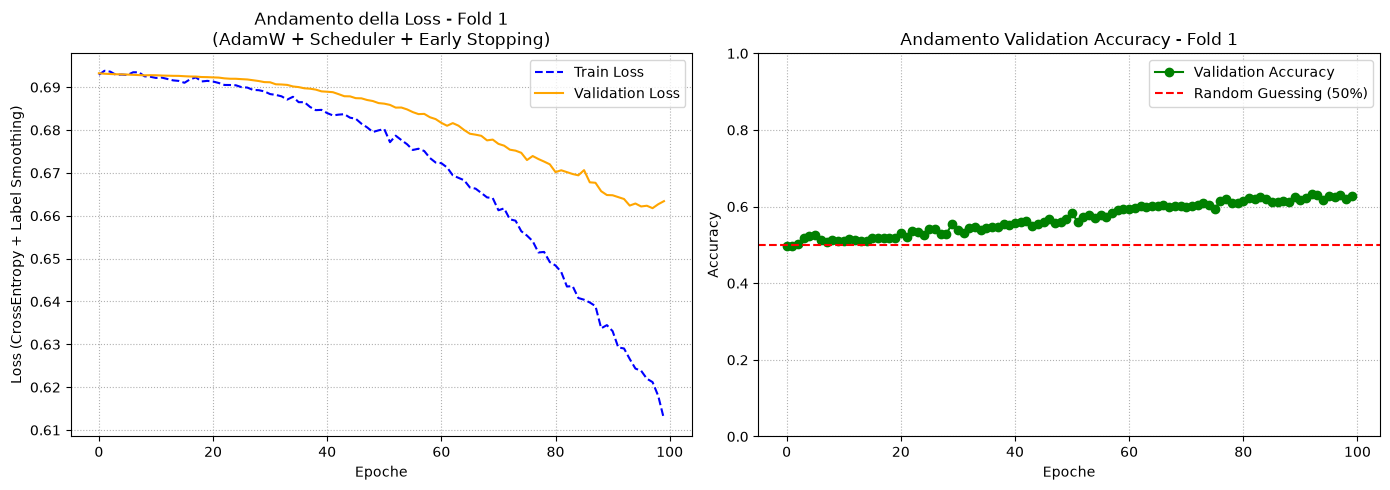

In [13]:

#PROVO 32

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt

# 1. Configurazione del Dispositivo (MPS / CUDA / CPU)
if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("🚀 Dispositivo rilevato: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print("🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("⚠️ Dispositivo rilevato: CPU")

# 2. Parametri di Configurazione
BATCH_SIZE = 32
EPOCHS = 100
LR = 1e-5
WEIGHT_DECAY = 1e-1
ALPHA_NOISE = 0.01

gkf = GroupKFold(n_splits=5)

# ==========================================
# 3. CICLO DI TRAINING CON FOLD E TRAINER PERSONALIZZATO
# ==========================================
for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- INIZIO TRAINING & VALIDAZIONE - FOLD {fold + 1}/5 (Batch Size = {BATCH_SIZE}) ---")

    # A. Divisione dei dati grezzi in base al fold del GroupKFold
    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]

    # B. Calcolo Media e Std per-canale ESCLUSIVAMENTE sul Training Set
    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    # C. Normalizzazione + Data Augmentation (Rumore Gaussiano) solo sul Train
    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    # D. Normalizzazione pura sul Validation Set (usando media e std del Train)
    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    # E. Creazione Dataset e DataLoader PyTorch
    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

    # F. Inizializzazione del Modello EEG Conformer
    model = EEGConformer(
        num_channels=64, time_steps=641, d_model=32, 
        nhead=4, num_layers=1, d_ff=128, dropout=0.4, num_classes=2
    ).to(device)
    
    # G. Ottimizzatore (AdamW), Loss (con Label Smoothing) e Scheduler (Cosine Annealing)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, 
        mode='min',       # Monitora la discesa della validation loss
        factor=0.5,       # Dimezza il learning rate quando si attiva (lr = lr * 0.5)
        patience=3,       # Se per 3 epoche la val loss non migliora, agisce
        )

    # H. Inizializzazione della tua classe EEGTrainer (che gestisce Early Stopper e Scheduler)
    trainer = EEGTrainer(
        model=model, 
        criterion=criterion, 
        optimizer=optimizer,  
        device=device
    )

    # I. Avvio dell'addestramento tramite il metodo della classe
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(
        train_loader=train_loader, 
        val_loader=val_loader, 
        epochs=EPOCHS,
        scheduler=scheduler
    )

    print(f"✅ Fold {fold + 1} completato | Miglior Val Acc: {best_val_acc:.4f} | Max Val Acc: {max(val_accuracies)*100:.2f}%")

    # ==========================================
    # L. PLOT DELLE CURVE DI LOSS E ACCURACY PER IL FOLD
    # ==========================================
    plt.figure(figsize=(14, 5))

    # Pannello 1: Loss
    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Andamento della Loss - Fold {fold + 1}\n(AdamW + Scheduler + Early Stopping)')
    plt.xlabel('Epoche')
    plt.ylabel('Loss (CrossEntropy + Label Smoothing)')
    plt.legend()
    plt.grid(True, linestyle=':')

    # Pannello 2: Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.axhline(y=0.5, color='red', linestyle='--', label='Random Guessing (50%)')
    plt.title(f'Andamento Validation Accuracy - Fold {fold + 1}')
    plt.xlabel('Epoche')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()

    break

# GroupKFold + ReduceLROnPlateau +  senzagradient clipping

🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)

--- INIZIO TRAINING & VALIDAZIONE - FOLD 1/5 (Batch Size = 64) ---
Epoch 01/30: train_loss=0.69926, val_loss=0.69287, val_acc=50.29%
Epoch 02/30: train_loss=0.69284, val_loss=0.69225, val_acc=52.03%
Epoch 03/30: train_loss=0.69136, val_loss=0.69175, val_acc=53.19%
Epoch 04/30: train_loss=0.69151, val_loss=0.69173, val_acc=54.24%
Epoch 05/30: train_loss=0.69042, val_loss=0.69067, val_acc=55.28%
Epoch 06/30: train_loss=0.68953, val_loss=0.69082, val_acc=55.05%
Epoch 07/30: train_loss=0.68623, val_loss=0.69077, val_acc=51.57%
Epoch 08/30: train_loss=0.68515, val_loss=0.68717, val_acc=54.82%
Epoch 09/30: train_loss=0.67982, val_loss=0.68470, val_acc=56.45%
Epoch 10/30: train_loss=0.67812, val_loss=0.68248, val_acc=59.81%
Epoch 11/30: train_loss=0.67259, val_loss=0.67892, val_acc=56.68%
Epoch 12/30: train_loss=0.66604, val_loss=0.67477, val_acc=58.89%
Epoch 13/30: train_loss=0.65564, val_loss=0.68083, val_acc=56.79%
Epoch 14/30: train_loss=0.65262,

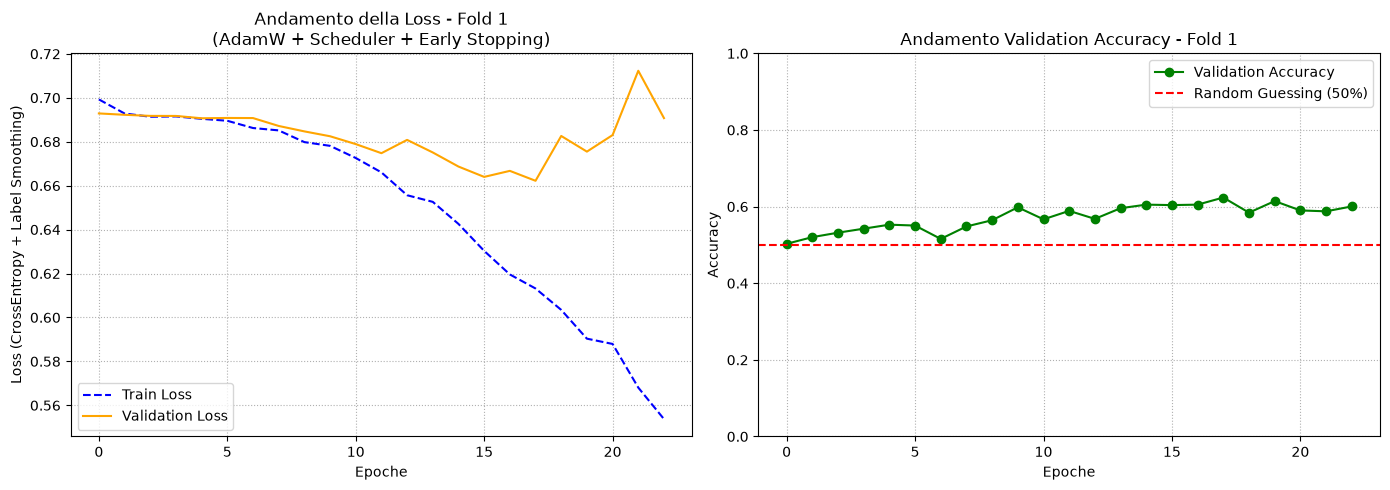


--- INIZIO TRAINING & VALIDAZIONE - FOLD 2/5 (Batch Size = 64) ---
Epoch 01/30: train_loss=0.69321, val_loss=0.69293, val_acc=51.68%
Epoch 02/30: train_loss=0.69282, val_loss=0.69228, val_acc=52.38%
Epoch 03/30: train_loss=0.69129, val_loss=0.69232, val_acc=51.45%
Epoch 04/30: train_loss=0.68983, val_loss=0.69269, val_acc=52.50%
Epoch 05/30: train_loss=0.68732, val_loss=0.69248, val_acc=53.54%
Epoch 06/30: train_loss=0.68629, val_loss=0.69180, val_acc=52.73%
Epoch 07/30: train_loss=0.68380, val_loss=0.69090, val_acc=54.94%
Epoch 08/30: train_loss=0.68073, val_loss=0.68832, val_acc=53.19%
Epoch 09/30: train_loss=0.67421, val_loss=0.68954, val_acc=56.21%
Epoch 10/30: train_loss=0.66724, val_loss=0.68427, val_acc=53.31%
Epoch 11/30: train_loss=0.66025, val_loss=0.68188, val_acc=57.49%
Epoch 12/30: train_loss=0.65809, val_loss=0.67945, val_acc=54.47%
Epoch 13/30: train_loss=0.64282, val_loss=0.67962, val_acc=57.84%
Epoch 14/30: train_loss=0.63395, val_loss=0.67364, val_acc=58.89%
Epoch 15

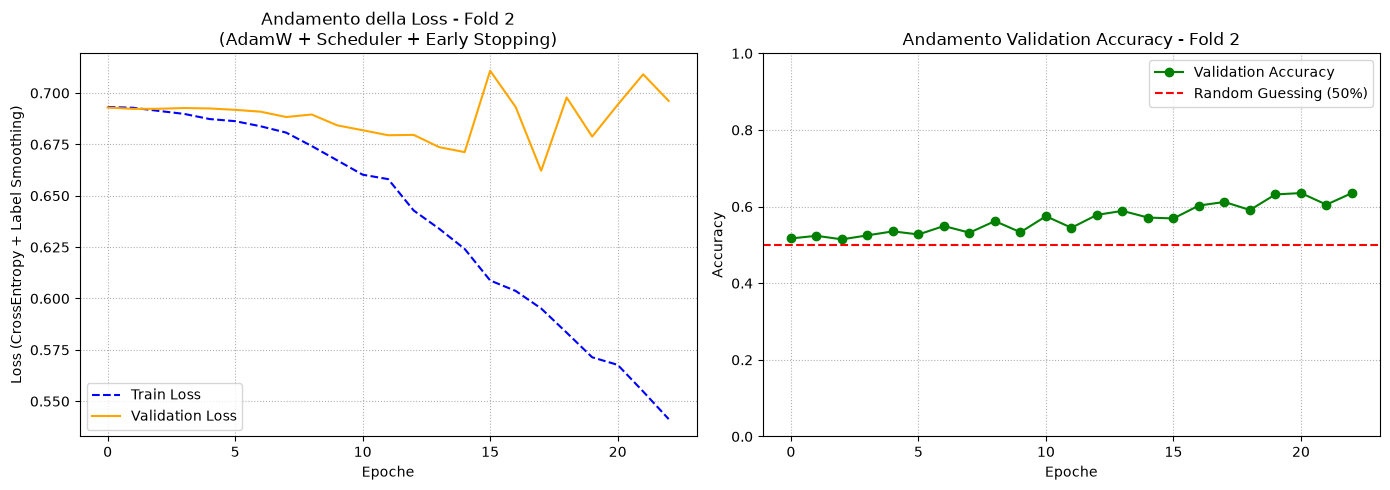


--- INIZIO TRAINING & VALIDAZIONE - FOLD 3/5 (Batch Size = 64) ---
Epoch 01/30: train_loss=0.69521, val_loss=0.69221, val_acc=50.56%
Epoch 02/30: train_loss=0.69206, val_loss=0.69091, val_acc=54.04%
Epoch 03/30: train_loss=0.69267, val_loss=0.68994, val_acc=53.92%
Epoch 04/30: train_loss=0.69144, val_loss=0.68893, val_acc=56.28%
Epoch 05/30: train_loss=0.69166, val_loss=0.68790, val_acc=56.61%
Epoch 06/30: train_loss=0.69114, val_loss=0.68633, val_acc=55.94%
Epoch 07/30: train_loss=0.68964, val_loss=0.68465, val_acc=58.18%
Epoch 08/30: train_loss=0.68923, val_loss=0.68283, val_acc=62.78%
Epoch 09/30: train_loss=0.68784, val_loss=0.68172, val_acc=64.35%
Epoch 10/30: train_loss=0.68627, val_loss=0.67826, val_acc=66.37%
Epoch 11/30: train_loss=0.68402, val_loss=0.67536, val_acc=64.46%
Epoch 12/30: train_loss=0.68119, val_loss=0.67416, val_acc=59.19%
Epoch 13/30: train_loss=0.67734, val_loss=0.66728, val_acc=61.55%
Epoch 14/30: train_loss=0.67085, val_loss=0.65532, val_acc=64.13%
Epoch 15

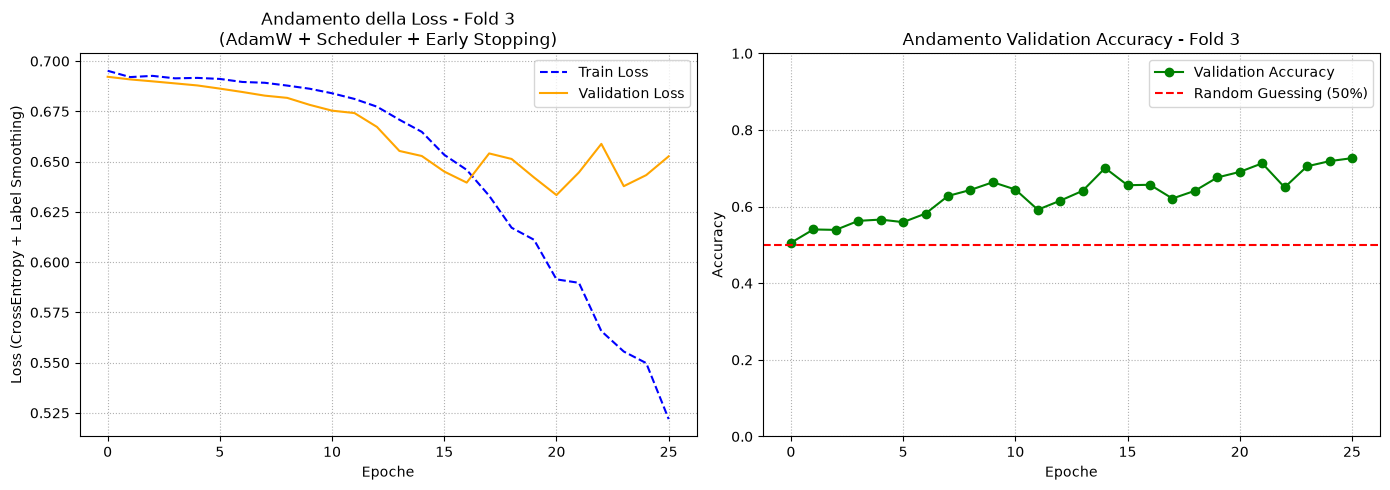


--- INIZIO TRAINING & VALIDAZIONE - FOLD 4/5 (Batch Size = 64) ---
Epoch 01/30: train_loss=0.69427, val_loss=0.69281, val_acc=51.12%
Epoch 02/30: train_loss=0.69311, val_loss=0.69220, val_acc=52.57%
Epoch 03/30: train_loss=0.69412, val_loss=0.69129, val_acc=52.46%
Epoch 04/30: train_loss=0.69220, val_loss=0.69066, val_acc=53.80%
Epoch 05/30: train_loss=0.69123, val_loss=0.68991, val_acc=54.36%
Epoch 06/30: train_loss=0.69123, val_loss=0.68872, val_acc=52.68%
Epoch 07/30: train_loss=0.69002, val_loss=0.68779, val_acc=53.02%
Epoch 08/30: train_loss=0.68929, val_loss=0.68657, val_acc=57.94%
Epoch 09/30: train_loss=0.68731, val_loss=0.68440, val_acc=60.18%
Epoch 10/30: train_loss=0.68544, val_loss=0.68333, val_acc=60.51%
Epoch 11/30: train_loss=0.68293, val_loss=0.68728, val_acc=52.91%
Epoch 12/30: train_loss=0.68053, val_loss=0.68451, val_acc=57.05%
Epoch 13/30: train_loss=0.67308, val_loss=0.68739, val_acc=54.92%
Epoch 14/30: train_loss=0.66785, val_loss=0.69381, val_acc=61.19%
Epoch 15

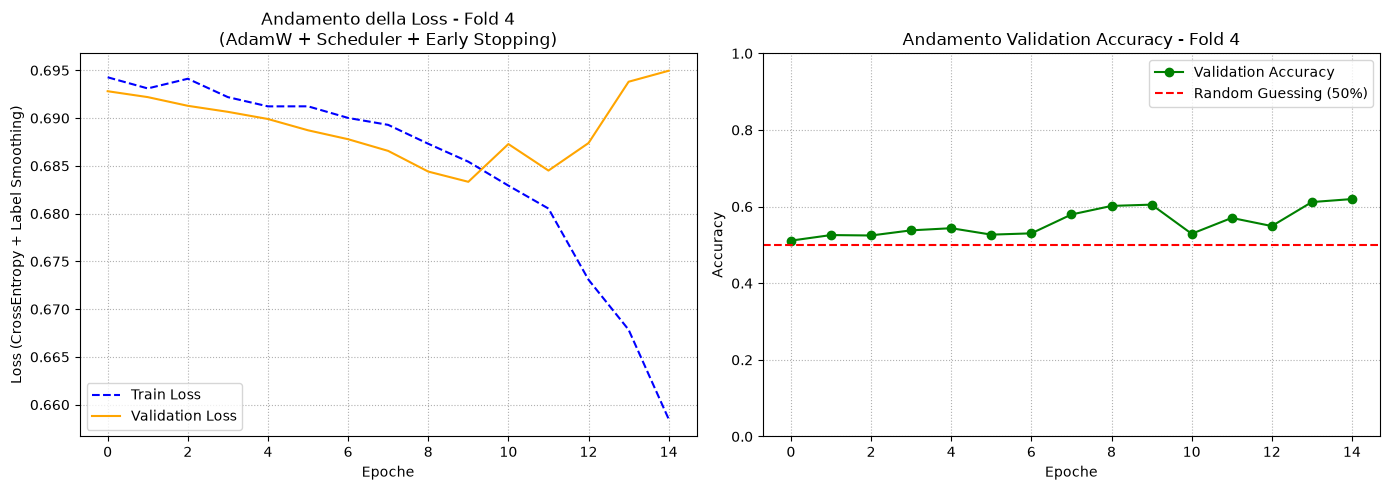


--- INIZIO TRAINING & VALIDAZIONE - FOLD 5/5 (Batch Size = 64) ---
Epoch 01/30: train_loss=0.69405, val_loss=0.69255, val_acc=52.57%
Epoch 02/30: train_loss=0.69266, val_loss=0.69174, val_acc=56.15%
Epoch 03/30: train_loss=0.69324, val_loss=0.69133, val_acc=57.05%
Epoch 04/30: train_loss=0.69045, val_loss=0.69066, val_acc=56.26%
Epoch 05/30: train_loss=0.69039, val_loss=0.69034, val_acc=54.36%
Epoch 06/30: train_loss=0.68760, val_loss=0.68853, val_acc=58.17%
Epoch 07/30: train_loss=0.68546, val_loss=0.68729, val_acc=60.40%
Epoch 08/30: train_loss=0.68258, val_loss=0.68387, val_acc=61.07%
Epoch 09/30: train_loss=0.68059, val_loss=0.68180, val_acc=56.82%
Epoch 10/30: train_loss=0.67490, val_loss=0.67982, val_acc=62.64%
Epoch 11/30: train_loss=0.66758, val_loss=0.67498, val_acc=59.17%
Epoch 12/30: train_loss=0.65960, val_loss=0.66985, val_acc=64.21%
Epoch 13/30: train_loss=0.64931, val_loss=0.66474, val_acc=58.05%
Epoch 14/30: train_loss=0.64212, val_loss=0.65433, val_acc=64.21%
Epoch 15

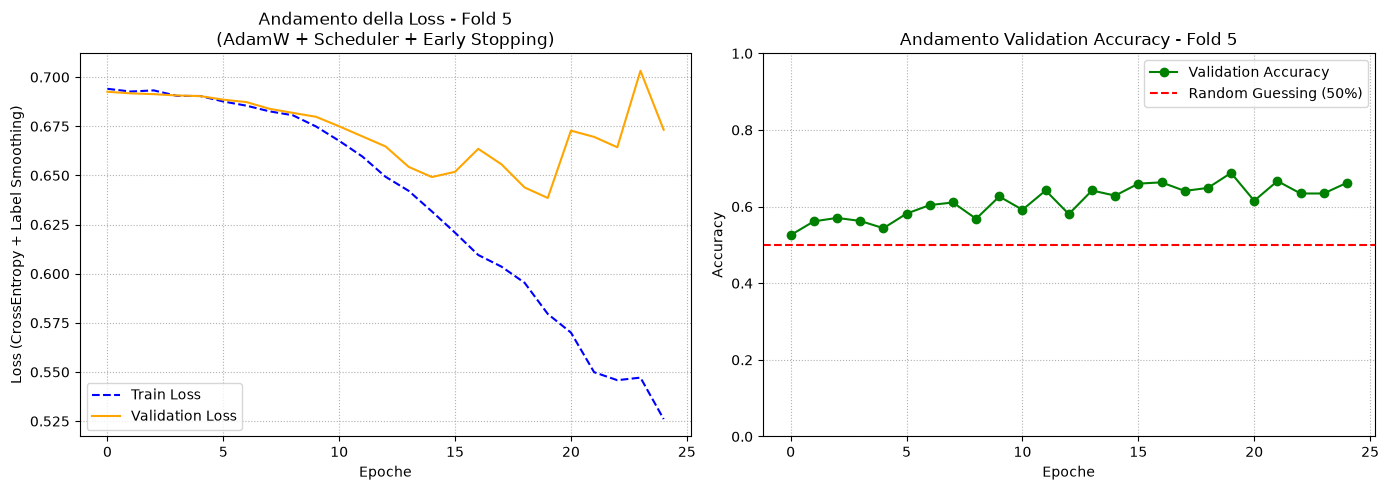

In [10]:
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt

# 1. Configurazione del Dispositivo (MPS / CUDA / CPU)
if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("🚀 Dispositivo rilevato: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print("🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("⚠️ Dispositivo rilevato: CPU")

# 2. Parametri di Configurazione
BATCH_SIZE = 64
EPOCHS = 30
LR = 1e-4
WEIGHT_DECAY = 1e-1
ALPHA_NOISE = 0.01

gkf = GroupKFold(n_splits=5)

# ==========================================
# 3. CICLO DI TRAINING CON FOLD E TRAINER PERSONALIZZATO
# ==========================================
for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- INIZIO TRAINING & VALIDAZIONE - FOLD {fold + 1}/5 (Batch Size = {BATCH_SIZE}) ---")

    # A. Divisione dei dati grezzi in base al fold del GroupKFold
    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]

    # B. Calcolo Media e Std per-canale ESCLUSIVAMENTE sul Training Set
    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    # C. Normalizzazione + Data Augmentation (Rumore Gaussiano) solo sul Train
    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    # D. Normalizzazione pura sul Validation Set (usando media e std del Train)
    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    # E. Creazione Dataset e DataLoader PyTorch
    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

    # F. Inizializzazione del Modello EEG Conformer
    model = EEGConformer(
        num_channels=64, time_steps=641, d_model=32, 
        nhead=4, num_layers=1, d_ff=128, dropout=0.4, num_classes=2
    ).to(device)
    
    # G. Ottimizzatore (AdamW), Loss (con Label Smoothing) e Scheduler (Cosine Annealing)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, 
        mode='min',       # Monitora la discesa della validation loss
        factor=0.5,       # Dimezza il learning rate quando si attiva (lr = lr * 0.5)
        patience=3,       # Se per 3 epoche la val loss non migliora, agisce
        )

    # H. Inizializzazione della tua classe EEGTrainer (che gestisce Early Stopper e Scheduler)
    trainer = EEGTrainer(
        model=model, 
        criterion=criterion, 
        optimizer=optimizer,  
        device=device
    )

    # I. Avvio dell'addestramento tramite il metodo della classe
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate_senza(
        train_loader=train_loader, 
        val_loader=val_loader, 
        epochs=EPOCHS,
        scheduler=scheduler
    )

    print(f"✅ Fold {fold + 1} completato | Miglior Val Acc: {best_val_acc:.4f} | Max Val Acc: {max(val_accuracies)*100:.2f}%")

    # ==========================================
    # L. PLOT DELLE CURVE DI LOSS E ACCURACY PER IL FOLD
    # ==========================================
    plt.figure(figsize=(14, 5))

    # Pannello 1: Loss
    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Andamento della Loss - Fold {fold + 1}\n(AdamW + Scheduler + Early Stopping)')
    plt.xlabel('Epoche')
    plt.ylabel('Loss (CrossEntropy + Label Smoothing)')
    plt.legend()
    plt.grid(True, linestyle=':')

    # Pannello 2: Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.axhline(y=0.5, color='red', linestyle='--', label='Random Guessing (50%)')
    plt.title(f'Andamento Validation Accuracy - Fold {fold + 1}')
    plt.xlabel('Epoche')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()

  

🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)

--- INIZIO TRAINING & VALIDAZIONE - FOLD 1/5 (Batch Size = 32) ---
Epoch 01/100: train_loss=0.69349, val_loss=0.69327, val_acc=49.59%
Epoch 02/100: train_loss=0.69352, val_loss=0.69322, val_acc=49.94%
Epoch 03/100: train_loss=0.69338, val_loss=0.69314, val_acc=50.41%
Epoch 04/100: train_loss=0.69374, val_loss=0.69306, val_acc=50.41%
Epoch 05/100: train_loss=0.69322, val_loss=0.69300, val_acc=52.03%
Epoch 06/100: train_loss=0.69277, val_loss=0.69296, val_acc=52.03%
Epoch 07/100: train_loss=0.69324, val_loss=0.69287, val_acc=52.85%
Epoch 08/100: train_loss=0.69354, val_loss=0.69280, val_acc=51.57%
Epoch 09/100: train_loss=0.69240, val_loss=0.69281, val_acc=52.85%
Epoch 10/100: train_loss=0.69352, val_loss=0.69273, val_acc=51.80%
Epoch 11/100: train_loss=0.69257, val_loss=0.69267, val_acc=52.03%
Epoch 12/100: train_loss=0.69245, val_loss=0.69262, val_acc=52.38%
Epoch 13/100: train_loss=0.69146, val_loss=0.69259, val_acc=51.45%
Epoch 14/100: train

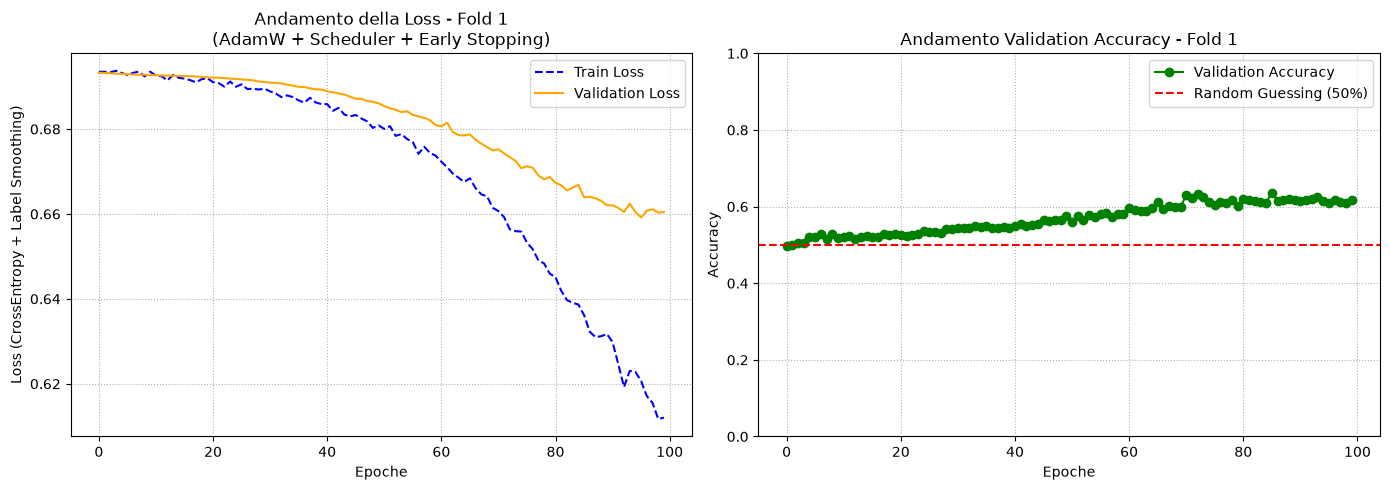

In [15]:

#PROVO 32

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt

# 1. Configurazione del Dispositivo (MPS / CUDA / CPU)
if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("🚀 Dispositivo rilevato: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print("🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("⚠️ Dispositivo rilevato: CPU")

# 2. Parametri di Configurazione
BATCH_SIZE = 32
EPOCHS = 100
LR = 1e-5
WEIGHT_DECAY = 1e-2
ALPHA_NOISE = 0.01

gkf = GroupKFold(n_splits=5)

# ==========================================
# 3. CICLO DI TRAINING CON FOLD E TRAINER PERSONALIZZATO
# ==========================================
for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- INIZIO TRAINING & VALIDAZIONE - FOLD {fold + 1}/5 (Batch Size = {BATCH_SIZE}) ---")

    # A. Divisione dei dati grezzi in base al fold del GroupKFold
    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]

    # B. Calcolo Media e Std per-canale ESCLUSIVAMENTE sul Training Set
    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    # C. Normalizzazione + Data Augmentation (Rumore Gaussiano) solo sul Train
    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    # D. Normalizzazione pura sul Validation Set (usando media e std del Train)
    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    # E. Creazione Dataset e DataLoader PyTorch
    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

    # F. Inizializzazione del Modello EEG Conformer
    model = EEGConformer(
        num_channels=64, time_steps=641, d_model=32, 
        nhead=4, num_layers=1, d_ff=128, dropout=0.4, num_classes=2
    ).to(device)
    
    # G. Ottimizzatore (AdamW), Loss (con Label Smoothing) e Scheduler (Cosine Annealing)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, 
        mode='min',       # Monitora la discesa della validation loss
        factor=0.5,       # Dimezza il learning rate quando si attiva (lr = lr * 0.5)
        patience=3,       # Se per 3 epoche la val loss non migliora, agisce
        )

    # H. Inizializzazione della tua classe EEGTrainer (che gestisce Early Stopper e Scheduler)
    trainer = EEGTrainer(
        model=model, 
        criterion=criterion, 
        optimizer=optimizer,  
        device=device
    )

    # I. Avvio dell'addestramento tramite il metodo della classe
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate_senza(
        train_loader=train_loader, 
        val_loader=val_loader, 
        epochs=EPOCHS,
        scheduler=scheduler
    )

    print(f"✅ Fold {fold + 1} completato | Miglior Val Acc: {best_val_acc:.4f} | Max Val Acc: {max(val_accuracies)*100:.2f}%")

    # ==========================================
    # L. PLOT DELLE CURVE DI LOSS E ACCURACY PER IL FOLD
    # ==========================================
    plt.figure(figsize=(14, 5))

    # Pannello 1: Loss
    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Andamento della Loss - Fold {fold + 1}\n(AdamW + Scheduler + Early Stopping)')
    plt.xlabel('Epoche')
    plt.ylabel('Loss (CrossEntropy + Label Smoothing)')
    plt.legend()
    plt.grid(True, linestyle=':')

    # Pannello 2: Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.axhline(y=0.5, color='red', linestyle='--', label='Random Guessing (50%)')
    plt.title(f'Andamento Validation Accuracy - Fold {fold + 1}')
    plt.xlabel('Epoche')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()

    break

# GFK grid search solo sul primo

## batch size 64, plateu e con gradiente clipping senza label

In [9]:
import itertools
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt

# ==========================================
# 1. CONFIGURAZIONE DEL DISPOSITIVO
# ==========================================
if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("🚀 Dispositivo rilevato: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print("🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("⚠️ Dispositivo rilevato: CPU")

# ==========================================
# 2. PARAMETRI GENERALI E GRID SEARCH
# ==========================================
BATCH_SIZE = 64
ALPHA_NOISE = 0.01

# Definizione dello spazio degli iperparametri da testare
param_grid = {
    'lr': [1e-3, 1e-4,1e-5],
    'dropout': [0.4, 0.3 ,0.5],
    'weight_decay': [1e-1, 1e-2]
}

keys = param_grid.keys()
combinations = [dict(zip(keys, prod)) for prod in itertools.product(*param_grid.values())]

gkf = GroupKFold(n_splits=5)

print(f"\n🧪 Spazio Grid Search definito: {len(combinations)} combinazioni da testare.")

# Estraiamo il primo fold di gruppo come riferimento per il tuning degli iperparametri
for train_idx, val_idx in gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation):
    X_train_t_raw = X_training_validation_raw[train_idx]
    y_train_t = y_training_validation[train_idx]
    X_val_t_raw = X_training_validation_raw[val_idx]
    y_val_t = y_training_validation[val_idx]
    break  # Ci basta il primo split per trovare i parametri

# Normalizzazione preliminare per il tuning
t_mean = np.mean(X_train_t_raw, axis=(0, 2), keepdims=True)  
t_std = np.std(X_train_t_raw, axis=(0, 2), keepdims=True)
epsilon = 1e-8

X_train_t_norm = (X_train_t_raw - t_mean) / (t_std + epsilon)
X_train_t_final = X_train_t_norm + (ALPHA_NOISE * np.random.randn(*X_train_t_norm.shape))
X_val_t_final = (X_val_t_raw - t_mean) / (t_std + epsilon)

train_loader_grid = DataLoader(EEGDataset(X_train_t_final, y_train_t), batch_size=BATCH_SIZE, shuffle=True)
val_loader_grid = DataLoader(EEGDataset(X_val_t_final, y_val_t), batch_size=BATCH_SIZE, shuffle=False)

best_overall_acc = 0.0
best_hyperparams = None
TUNING_EPOCHS = 30  

print("\n==========================================")
print("🔍 INIZIO GRID SEARCH (CROSS-SUBJECT)")
print("==========================================")

for i, params in enumerate(combinations):
    print(f"Test {i+1}/{len(combinations)} | LR: {params['lr']} | Dropout: {params['dropout']} | WD: {params['weight_decay']}")
    
    model_t = EEGConformer(
        num_channels=64, time_steps=641, d_model=32, 
        nhead=4, num_layers=1, d_ff=128, dropout=params['dropout'], num_classes=2
    ).to(device)
    
    criterion_t = nn.CrossEntropyLoss(label_smoothing=0.0)
    optimizer_t = optim.AdamW(model_t.parameters(), lr=params['lr'], weight_decay=params['weight_decay'])
    scheduler_t = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer=optimizer_t, 
            mode='min',       # Monitora la discesa della validation loss
            factor=0.5,       # Dimezza il learning rate quando si attiva (lr = lr * 0.5)
            patience=5,       # Se per 3 epoche la val loss non migliora, agisce
            )
    trainer_t = EEGTrainer(model=model_t, criterion=criterion_t, optimizer=optimizer_t, device=device)
    trainer_t.scheduler = scheduler_t

    _, _, _, val_accs_t = trainer_t.train_and_validate(
        train_loader=train_loader_grid, val_loader=val_loader_grid, epochs=TUNING_EPOCHS, scheduler = scheduler_t
    )

    current_max_acc = max(val_accs_t)
    if current_max_acc > best_overall_acc:
        best_overall_acc = current_max_acc
        best_hyperparams = params
        print(f"🎉 Nuovo record provvisorio! Max Accuracy: {best_overall_acc * 100:.2f}%")

print(f"\n🏆 CONFIGURAZIONE VINCENTE TROVATA DALLA GRID SEARCH:")
print(f"   - Parametri: {best_hyperparams}")
print(f"   - Max Accuracy di Tuning: {best_overall_acc * 100:.2f}%\n")



🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)

🧪 Spazio Grid Search definito: 18 combinazioni da testare.

🔍 INIZIO GRID SEARCH (CROSS-SUBJECT)
Test 1/18 | LR: 0.001 | Dropout: 0.4 | WD: 0.1
Epoch 01/30: train_loss=0.69410, val_loss=0.69345, val_acc=49.83%
Epoch 02/30: train_loss=0.69358, val_loss=0.69339, val_acc=49.83%
Epoch 03/30: train_loss=0.69291, val_loss=0.69195, val_acc=53.19%
Epoch 04/30: train_loss=0.68638, val_loss=0.69197, val_acc=54.70%
Epoch 05/30: train_loss=0.67512, val_loss=0.69150, val_acc=56.21%
Epoch 06/30: train_loss=0.66026, val_loss=0.69270, val_acc=55.87%
Epoch 07/30: train_loss=0.63127, val_loss=0.68230, val_acc=59.47%
Epoch 08/30: train_loss=0.61027, val_loss=0.65836, val_acc=60.86%
Epoch 09/30: train_loss=0.57904, val_loss=0.74067, val_acc=63.41%
Epoch 10/30: train_loss=0.54633, val_loss=0.77849, val_acc=61.44%
Epoch 11/30: train_loss=0.54698, val_loss=0.74815, val_acc=63.30%
Epoch 12/30: train_loss=0.51212, val_loss=0.69516, val_acc=65.51%
Epoch 13/30: train_lo

🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)

--- INIZIO TRAINING & VALIDAZIONE - FOLD 1/5 (Batch Size = 64) ---
Epoch 01/30: train_loss=0.69490, val_loss=0.69328, val_acc=50.29%
Epoch 02/30: train_loss=0.69391, val_loss=0.69343, val_acc=53.31%
Epoch 03/30: train_loss=0.69104, val_loss=0.69327, val_acc=50.87%
Epoch 04/30: train_loss=0.68875, val_loss=0.68772, val_acc=54.12%
Epoch 05/30: train_loss=0.67908, val_loss=0.68132, val_acc=57.49%
Epoch 06/30: train_loss=0.66699, val_loss=0.69845, val_acc=55.05%
Epoch 07/30: train_loss=0.63445, val_loss=0.68129, val_acc=58.65%
Epoch 08/30: train_loss=0.61791, val_loss=0.70014, val_acc=58.54%
Epoch 09/30: train_loss=0.60305, val_loss=0.67272, val_acc=63.65%
Epoch 10/30: train_loss=0.58928, val_loss=0.82896, val_acc=54.59%
Epoch 11/30: train_loss=0.57414, val_loss=0.64665, val_acc=66.43%
Epoch 12/30: train_loss=0.54635, val_loss=0.68647, val_acc=65.74%
Epoch 13/30: train_loss=0.53860, val_loss=0.65709, val_acc=66.90%
Epoch 14/30: train_loss=0.51142,

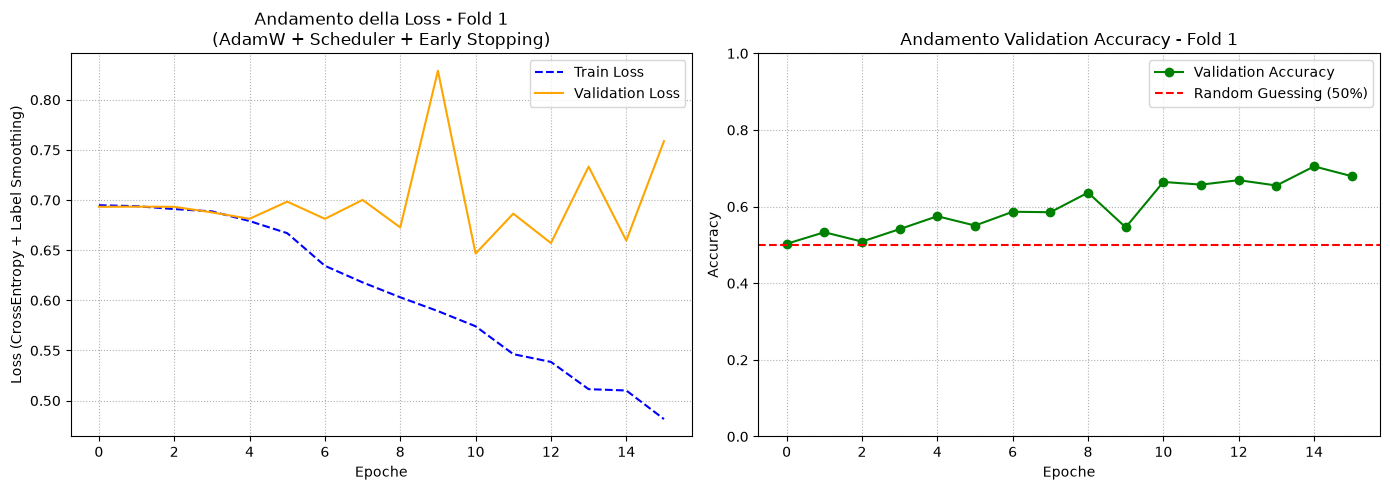


--- INIZIO TRAINING & VALIDAZIONE - FOLD 2/5 (Batch Size = 64) ---
Epoch 01/30: train_loss=0.69579, val_loss=0.69399, val_acc=49.83%
Epoch 02/30: train_loss=0.69285, val_loss=0.69359, val_acc=49.83%
Epoch 03/30: train_loss=0.69187, val_loss=0.69093, val_acc=50.17%
Epoch 04/30: train_loss=0.68080, val_loss=0.68881, val_acc=52.73%
Epoch 05/30: train_loss=0.66665, val_loss=0.76203, val_acc=51.10%
Epoch 06/30: train_loss=0.65199, val_loss=0.74113, val_acc=54.12%
Epoch 07/30: train_loss=0.63529, val_loss=0.66625, val_acc=61.79%
Epoch 08/30: train_loss=0.61988, val_loss=0.68806, val_acc=60.98%
Epoch 09/30: train_loss=0.61334, val_loss=0.70071, val_acc=59.47%
Epoch 10/30: train_loss=0.59806, val_loss=0.70603, val_acc=60.39%
Epoch 11/30: train_loss=0.58169, val_loss=0.68747, val_acc=62.72%
Epoch 12/30: train_loss=0.56516, val_loss=0.72141, val_acc=58.19%
Early stopping all'epoca 12
✅ Fold 2 completato | Miglior Val Acc: 0.6272 | Max Val Acc: 62.72%


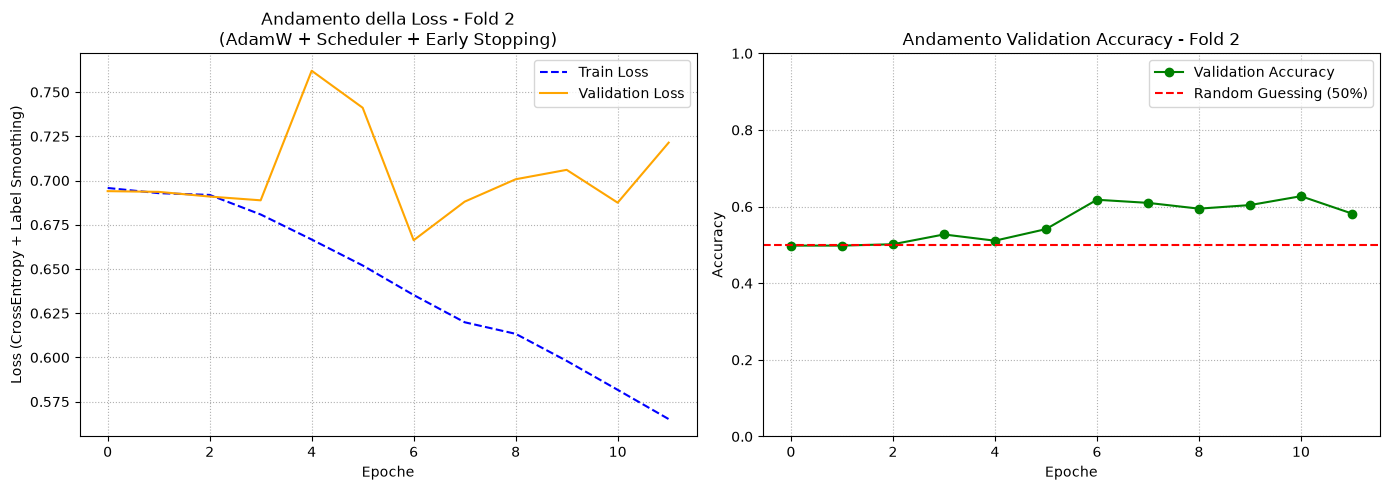


--- INIZIO TRAINING & VALIDAZIONE - FOLD 3/5 (Batch Size = 64) ---
Epoch 01/30: train_loss=0.69490, val_loss=0.69290, val_acc=50.67%
Epoch 02/30: train_loss=0.69465, val_loss=0.69157, val_acc=52.24%
Epoch 03/30: train_loss=0.69356, val_loss=0.68967, val_acc=54.82%
Epoch 04/30: train_loss=0.69237, val_loss=0.68721, val_acc=53.59%
Epoch 05/30: train_loss=0.69002, val_loss=0.67872, val_acc=55.49%
Epoch 06/30: train_loss=0.68174, val_loss=0.64842, val_acc=60.31%
Epoch 07/30: train_loss=0.66811, val_loss=0.62994, val_acc=65.02%
Epoch 08/30: train_loss=0.64705, val_loss=0.71249, val_acc=57.40%
Epoch 09/30: train_loss=0.63578, val_loss=0.63419, val_acc=64.69%
Epoch 10/30: train_loss=0.60821, val_loss=0.60550, val_acc=68.05%
Epoch 11/30: train_loss=0.59546, val_loss=0.60068, val_acc=71.52%
Epoch 12/30: train_loss=0.57726, val_loss=0.69639, val_acc=63.23%
Epoch 13/30: train_loss=0.56985, val_loss=0.56912, val_acc=79.26%
Epoch 14/30: train_loss=0.53984, val_loss=0.57912, val_acc=77.02%
Epoch 15

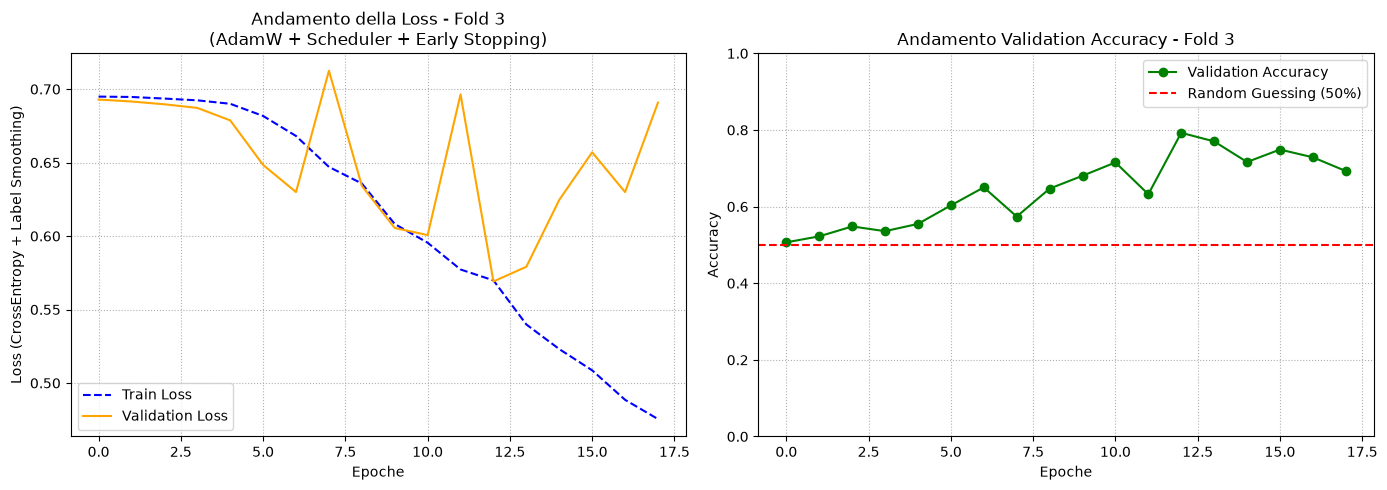


--- INIZIO TRAINING & VALIDAZIONE - FOLD 4/5 (Batch Size = 64) ---
Epoch 01/30: train_loss=0.69515, val_loss=0.69246, val_acc=51.23%
Epoch 02/30: train_loss=0.69386, val_loss=0.69134, val_acc=51.45%
Epoch 03/30: train_loss=0.69246, val_loss=0.68760, val_acc=54.03%
Epoch 04/30: train_loss=0.68577, val_loss=0.68584, val_acc=56.15%
Epoch 05/30: train_loss=0.66970, val_loss=0.69335, val_acc=59.51%
Epoch 06/30: train_loss=0.66036, val_loss=0.73006, val_acc=58.50%
Epoch 07/30: train_loss=0.65104, val_loss=0.71251, val_acc=62.19%
Epoch 08/30: train_loss=0.62562, val_loss=0.75343, val_acc=60.74%
Epoch 09/30: train_loss=0.61317, val_loss=0.71474, val_acc=61.86%
Early stopping all'epoca 9
✅ Fold 4 completato | Miglior Val Acc: 0.6219 | Max Val Acc: 62.19%


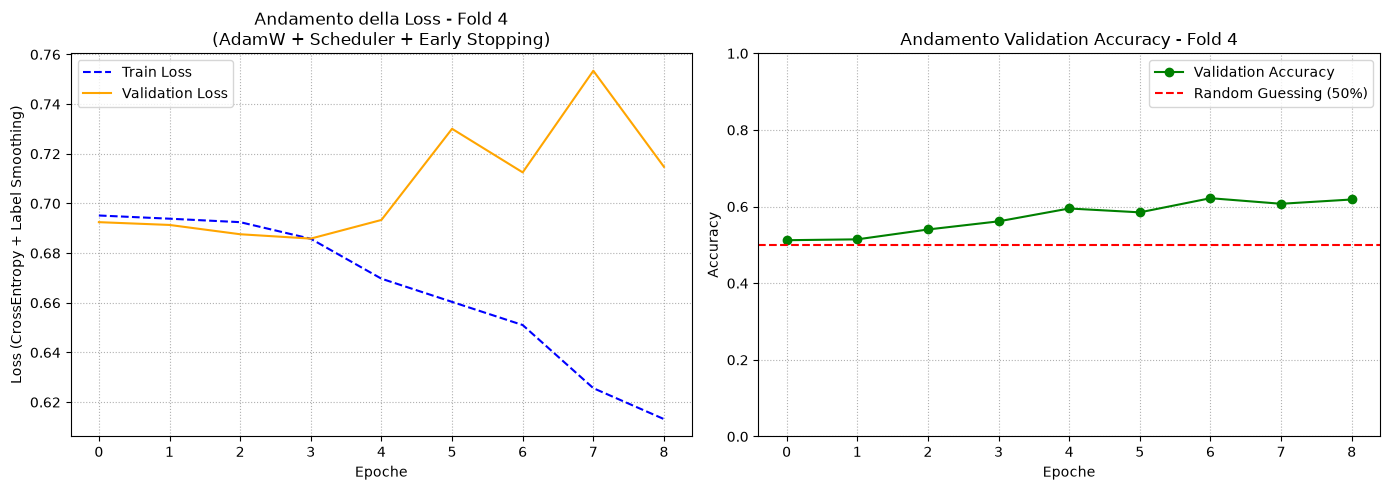


--- INIZIO TRAINING & VALIDAZIONE - FOLD 5/5 (Batch Size = 64) ---
Epoch 01/30: train_loss=0.69596, val_loss=0.69312, val_acc=50.11%
Epoch 02/30: train_loss=0.69514, val_loss=0.69247, val_acc=50.00%
Epoch 03/30: train_loss=0.69239, val_loss=0.68890, val_acc=54.81%
Epoch 04/30: train_loss=0.68315, val_loss=0.68072, val_acc=54.59%
Epoch 05/30: train_loss=0.66727, val_loss=0.65643, val_acc=65.32%
Epoch 06/30: train_loss=0.66027, val_loss=0.65525, val_acc=60.18%
Epoch 07/30: train_loss=0.64183, val_loss=0.65988, val_acc=67.67%
Epoch 08/30: train_loss=0.61754, val_loss=0.63501, val_acc=65.21%
Epoch 09/30: train_loss=0.59999, val_loss=0.63728, val_acc=66.33%
Epoch 10/30: train_loss=0.58182, val_loss=0.62923, val_acc=67.56%
Epoch 11/30: train_loss=0.55718, val_loss=0.72358, val_acc=62.64%
Epoch 12/30: train_loss=0.53986, val_loss=0.70209, val_acc=69.91%
Epoch 13/30: train_loss=0.53543, val_loss=0.80327, val_acc=62.08%
Epoch 14/30: train_loss=0.51460, val_loss=0.62994, val_acc=71.81%
Epoch 15

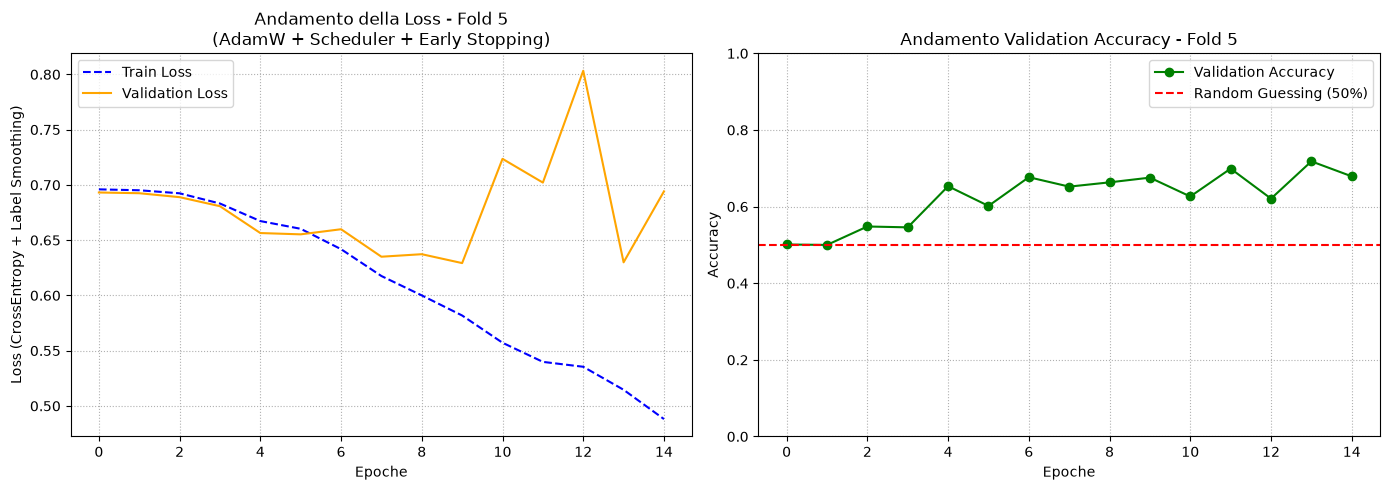

In [ ]:
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt

# 1. Configurazione del Dispositivo (MPS / CUDA / CPU)
if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("🚀 Dispositivo rilevato: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print("🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("⚠️ Dispositivo rilevato: CPU")

# 2. Parametri di Configurazione
BATCH_SIZE = 64
EPOCHS = 30
LR = 0.001
WEIGHT_DECAY = 0.01
ALPHA_NOISE = 0.01

gkf = GroupKFold(n_splits=5)

# ==========================================
# 3. CICLO DI TRAINING CON FOLD E TRAINER PERSONALIZZATO
# ==========================================
for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- INIZIO TRAINING & VALIDAZIONE - FOLD {fold + 1}/5 (Batch Size = {BATCH_SIZE}) ---")

    # A. Divisione dei dati grezzi in base al fold del GroupKFold
    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]

    # B. Calcolo Media e Std per-canale ESCLUSIVAMENTE sul Training Set
    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    # C. Normalizzazione + Data Augmentation (Rumore Gaussiano) solo sul Train
    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    # D. Normalizzazione pura sul Validation Set (usando media e std del Train)
    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    # E. Creazione Dataset e DataLoader PyTorch
    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

    # F. Inizializzazione del Modello EEG Conformer
    model = EEGConformer(
        num_channels=64, time_steps=641, d_model=32, 
        nhead=4, num_layers=1, d_ff=128, dropout=0.4, num_classes=2
    ).to(device)
    
    # G. Ottimizzatore (AdamW), Loss (con Label Smoothing) e Scheduler (Cosine Annealing)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, 
        mode='min',       # Monitora la discesa della validation loss
        factor=0.5,       # Dimezza il learning rate quando si attiva (lr = lr * 0.5)
        patience=5,       # Se per 3 epoche la val loss non migliora, agisce
        )

    # H. Inizializzazione della tua classe EEGTrainer (che gestisce Early Stopper e Scheduler)
    trainer = EEGTrainer(
        model=model, 
        criterion=criterion, 
        optimizer=optimizer,  
        device=device
    )

    # I. Avvio dell'addestramento tramite il metodo della classe
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate_senza(
        train_loader=train_loader, 
        val_loader=val_loader, 
        epochs=EPOCHS,
        scheduler=scheduler
    )

    print(f"✅ Fold {fold + 1} completato | Miglior Val Acc: {best_val_acc:.4f} | Max Val Acc: {max(val_accuracies)*100:.2f}%")

    # ==========================================
    # L. PLOT DELLE CURVE DI LOSS E ACCURACY PER IL FOLD
    # ==========================================
    plt.figure(figsize=(14, 5))

    # Pannello 1: Loss
    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Andamento della Loss - Fold {fold + 1}\n(AdamW + Scheduler + Early Stopping)')
    plt.xlabel('Epoche')
    plt.ylabel('Loss (CrossEntropy + Label Smoothing)')
    plt.legend()
    plt.grid(True, linestyle=':')

    # Pannello 2: Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.axhline(y=0.5, color='red', linestyle='--', label='Random Guessing (50%)')
    plt.title(f'Andamento Validation Accuracy - Fold {fold + 1}')
    plt.xlabel('Epoche')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()

  